# Introduction to numerical algorithms
## Practice class 11: Minimization

Today we write simple gradient methods, try the minimizers of SciPy, fit a curve by minimization, and solve the travelling salesman problem with simulated annealing.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize

rng = np.random.default_rng(2026)

### Useful commands

| Command | Meaning |
| --- | --- |
| `res = optimize.minimize(f, x0, method="CG")` | Minimize `f` starting from `x0` |
| `optimize.minimize(..., jac=df)` | Give the gradient too |
| `optimize.minimize(..., method="Nelder-Mead")` | Downhill simplex, no derivative needed |
| `optimize.minimize(..., callback=path.append)` | Save the position after each iteration |
| `res.x`, `res.fun`, `res.nit`, `res.nfev` | Position, value, iterations, function calls |
| `optimize.minimize(f, x0, args=(x, y))` | Pass extra arguments to `f(p, x, y)` |
| `gx, gy = np.meshgrid(xs, ys)`, `plt.contourf(gx, gy, F)` | Contour plot of a 2D function |
| `np.linalg.norm(v)` | Length of a vector |

### Task 1: Gradient method in 1D

#### 1a. Fixed step

To find a minimum of $f(x)$ we step against the derivative:

$$x_{n+1}=x_n-\gamma f'(x_n).$$

If $\gamma$ is small enough, $f$ gets smaller at every step. Stop when the step $|x_{n+1}-x_n|$ is smaller than `precision`, or after `max_iters` steps.

Write `simple_gradient`. It gets the derivative `df` and returns the final $x$ and the number of steps.

In [2]:
def simple_gradient(df, x0, gamma=0.01, precision=1e-6, max_iters=10000):
    x = x0
    iters = 0
    
    while iters < max_iters:
        x_new = x - gamma*df(x)
        if np.linalg.norm(x_new - x) < precision:
            break
        x = x_new
        iters += 1
    return x, iters

Try it on $f(x)=(x+5)^2$ from $x_0=3$. The minimum is at $x=-5$.

Then try $\gamma = 0.01,\ 0.1,\ 0.5,\ 0.9,\ 1.0,\ 1.1$ with `max_iters=1000`.
* Which $\gamma$ gets there in one step? Why? ($f''(x)=2$.)
* What happens if $\gamma\geq1$? Use $x_{n+1}+5=(1-2\gamma)(x_n+5)$.

In [4]:
df_quad = lambda x: 2 * (x + 5)

# Work Here!
x0 = 3

x_min, iters = simple_gradient(df_quad, x0)
print(f"Minimum found at x = {x_min} after {iters} iterations.")


Minimum found at x = -4.999950866358997 after 594 iterations.


#### 1b. Changing step

Near a minimum $f$ looks like a parabola, $f(x)\approx\beta(x-a)^2$. For a parabola the best step is $\gamma=1/(2\beta)$, which jumps right to $a$. We can estimate it from the last two points:

$$\gamma_n=\left|\frac{x_n-x_{n-1}}{f'(x_n)-f'(x_{n-1})}\right| .$$

Write `gradient_adaptive`. Make the first step with the given `gamma`, then update $\gamma$ after every step. If $f'(x_n)=f'(x_{n-1})$, stop, otherwise you divide by zero.

Compare the number of steps of the two methods for
* $f(x)=(x+5)^2$ from $x_0=3$,
* $f(x)=x^3-x$ from $x_0=3$ (minimum at $1/\sqrt3$).

In [13]:
def gradient_adaptive(df, x0, gamma=0.01, precision=1e-6, max_iters=10000):
    x = x0
    iters = 0
    # Work Here!
    while iters < max_iters:
        x_new = x - gamma*df(x)
        if np.linalg.norm(x_new - x) < precision:
            break
        gamma = np.abs((x_new-x)/(df(x_new)-df(x)))
        x = x_new
        iters += 1
    return x, iters

In [14]:
df_cubic = lambda x: 3 * x**2 - 1

# Work Here! Print position and number of steps for both methods and both functions.

x0 = 3
x_min, iters = simple_gradient(df_cubic, x0)
x_min_adaptive, iters_adaptive = gradient_adaptive(df_cubic, x0)
print(f"Simple Gradient: Minimum found at x = {x_min} after {iters} iterations.")
print(f"Adaptive Gradient: Minimum found at x = {x_min_adaptive} after {iters_adaptive} iterations.")

x_min_quad, iters_quad = simple_gradient(df_quad, x0)
x_min_quad_adaptive, iters_quad_adaptive = gradient_adaptive(df_quad, x0)
print(f"Simple Gradient (Quadratic): Minimum found at x = {x_min_quad} after {iters_quad} iterations.")
print(f"Adaptive Gradient (Quadratic): Minimum found at x = {x_min_quad_adaptive} after {iters_quad_adaptive} iterations.")

Simple Gradient: Minimum found at x = 0.5773784769636913 after 289 iterations.
Adaptive Gradient: Minimum found at x = 0.577351181286138 after 8 iterations.
Simple Gradient (Quadratic): Minimum found at x = -4.999950866358997 after 594 iterations.
Adaptive Gradient (Quadratic): Minimum found at x = -5.0 after 2 iterations.


### Task 2: Minimization in 2D

In more dimensions we step against the gradient:

$$\mathbf x_{n+1}=\mathbf x_n-\gamma_n\nabla F(\mathbf x_n),$$

and the step size is

$$\gamma_n=\frac{\left|(\mathbf x_n-\mathbf x_{n-1})^T\left[\nabla F(\mathbf x_n)-\nabla F(\mathbf x_{n-1})\right]\right|}{\left\|\nabla F(\mathbf x_n)-\nabla F(\mathbf x_{n-1})\right\|^2}.$$

#### 2a. Your own method

Test function:

$$F(x,y)=(x-1)^2+(x+y)^2,$$

with the minimum at $(1,-1)$.

1. Calculate the gradient by hand and write `dF2`.
2. Write `gradient_nd`. It is the same as `gradient_adaptive`, but with vectors (use `np.dot` and `np.linalg.norm`). Save every position in `path` (use `.copy()`).
3. Start from $(3,3)$ and draw the path with `plot_paths`.

In [15]:
def F2(p):
    x, y = p[0], p[1]
    return (x - 1)**2 + (x + y)**2


def dF2(p):
    x, y = p[0], p[1]
    # Work Here! Return the gradient as np.array([dF/dx, dF/dy]).
    dF_dx = 2 * (x - 1) + 2 * (x + y)
    dF_dy = 2 * (x + y)
    return np.array([dF_dx, dF_dy])


def gradient_nd(dF, x0, gamma=0.01, precision=1e-8, max_iters=10000):
    x = np.array(x0, dtype=float)
    path = [x.copy()]
    # Work Here!
    for _ in range(max_iters):
        x_new = x - gamma * dF(x)
        path.append(x_new.copy())
        if np.linalg.norm(x_new - x) < precision:
            break
        x = x_new
    return x, np.array(path)


def plot_paths(F, paths, xlim, ylim, log=False, ng=200):
    gx, gy = np.meshgrid(np.linspace(*xlim, ng), np.linspace(*ylim, ng))
    values = F(np.array([gx, gy]))
    if log:
        values = np.log10(values + 1e-3)
    plt.figure(figsize=(6, 5))
    plt.contourf(gx, gy, values, levels=30, cmap="gray")
    plt.colorbar(label="log10 F" if log else "F")
    for label, path in paths.items():
        path = np.array(path)
        plt.plot(path[:, 0], path[:, 1], "o-", ms=3, label=f"{label} ({len(path) - 1} steps)")
    plt.xlim(xlim); plt.ylim(ylim)
    plt.xlabel("x"); plt.ylabel("y"); plt.legend()
    plt.show()

Minimum: [ 0.99999931 -0.99999889]  steps: 1879


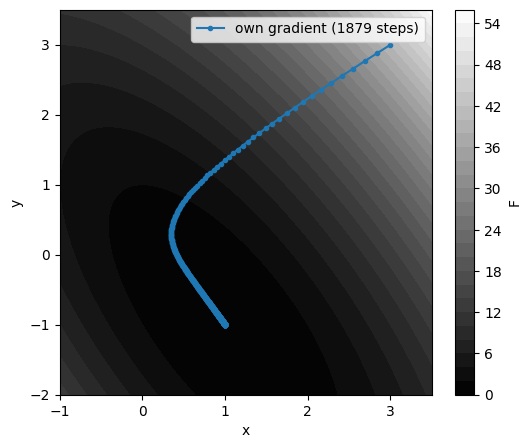

In [16]:
x_min, path_own = gradient_nd(dF2, [3, 3])
print("Minimum:", x_min, " steps:", len(path_own) - 1)
plot_paths(F2, {"own gradient": path_own}, xlim=(-1, 3.5), ylim=(-2, 3.5))

#### 2b. SciPy

Two methods of `optimize.minimize`:

* **CG** (conjugate gradient) uses the gradient. Without `jac` it calculates the gradient numerically, which needs extra function calls.
* **Nelder-Mead** (downhill simplex, see the lecture) uses only function values. It moves a triangle towards the minimum.

Minimize $F$ from $(3,3)$ with CG, CG with `jac=dF2`, and Nelder-Mead. Save the paths with `callback` (put the starting point in the list first). Print `res.x`, `res.nit` and `res.nfev`, and draw all paths together with yours.

Which one needs the fewest function calls? Why is the number of iterations not enough to compare them?

Scipy minimum:  [ 0.99999993 -1.00000066]  Nit:  6  steps: 7
Scipy Nelder-Mead minimum:  [ 0.99999754 -1.00002523]  Nit:  50  steps: 97


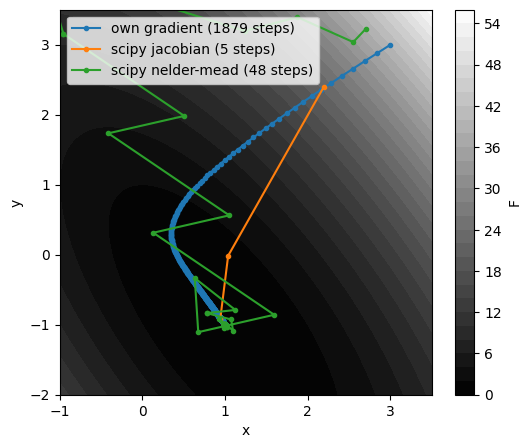

In [35]:
# Work Here!
path_scipy = []
def callback_scipy(xk):
    path_scipy.append(xk.copy())

min_scipy_jac = optimize.minimize(F2, [3, 3], jac=dF2, callback=callback_scipy)
print("Scipy minimum: ", min_scipy_jac.x, " Nit: ", min_scipy_jac.nit, " steps:", min_scipy_jac.nfev)

path_jac = np.array(path_scipy)
path_scipy = []  # Reset path for Nelder-Mead

min_scipy_nelder = optimize.minimize(F2, [3, 3], method='Nelder-Mead', callback=callback_scipy)
print("Scipy Nelder-Mead minimum: ", min_scipy_nelder.x, " Nit: ", min_scipy_nelder.nit, " steps:", min_scipy_nelder.nfev)
path_nelder = np.array(path_scipy)

plot_paths(F2,{
    "own gradient": path_own,
    "scipy jacobian": path_jac,
    "scipy nelder-mead": path_nelder
}, xlim=(-1, 3.5), ylim=(-2, 3.5))

### Task 3: Fitting is minimization

In class 9 we used `curve_fit`. It minimizes the squared error

$$E(\mathbf p)=\sum_i\bigl(y_i-\hat y(x_i;\mathbf p)\bigr)^2 .$$

Now do it with `optimize.minimize`. The data are

$$y=A\sin\bigl(\omega(x+\varphi)\bigr)+\text{noise},\qquad A=1.3,\ \omega=2,\ \varphi=0.5.$$

1. Write `loss(p, x, y)` with `p = [A, omega, phi]`, without a loop.
2. Minimize it with `optimize.minimize(loss, x0, args=(x_sin, y_sin), method="CG")` from `x0 = [1, 2, 0]`. Plot the data and the fit.
3. Also start from `[1, 1, 0]` and `[1, 2, 2]`. Print the parameters and $E$, and plot the fits.
   * One of them gets stuck in a local minimum. The fit is bad and $E$ is large.
   * The other fits well, but with other parameters. Why do $(A,\omega,\varphi)$, $(-A,\omega,\varphi+\pi/\omega)$ and $(A,\omega,\varphi+2\pi/\omega)$ give the same curve?

x0 = [1, 2, 0]: A = 1.254263, omega = 1.994630, phi = 0.512543, E = 7.563042
x0 = [1, 1, 0]: A = -0.198236, omega = 0.544696, phi = -2.224657, E = 168.784484
x0 = [1, 2, 2]: A = 1.254263, omega = 1.994630, phi = 0.512543, E = 7.563042


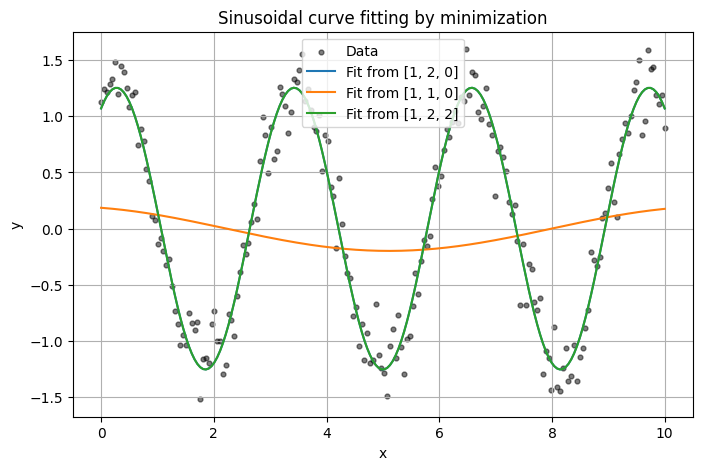

In [37]:
x_sin = np.linspace(0, 10, 200)
y_sin = 1.3 * np.sin(2 * (x_sin + 0.5)) + rng.normal(0, 0.2, x_sin.size)


def loss(p, x, y):
    A, omega, phi = p
    y_hat = A * np.sin(omega * (x + phi))
    return np.sum((y - y_hat)**2)

initial_guesses = ([1, 2, 0], [1, 1, 0], [1, 2, 2])

plt.figure(figsize=(8, 5))
plt.scatter(x_sin, y_sin, s=12, color="black", alpha=0.5, label="Data")

for x0 in initial_guesses:
    result = optimize.minimize(loss, x0, args=(x_sin, y_sin), method="CG")
    A, omega, phi = result.x
    y_fit = A * np.sin(omega * (x_sin + phi))

    print(f"x0 = {x0}: A = {A:.6f}, omega = {omega:.6f}, phi = {phi:.6f}, E = {result.fun:.6f}")
    plt.plot(x_sin, y_fit, label=f"Fit from {x0}")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Sinusoidal curve fitting by minimization")
plt.legend()
plt.grid(True)
plt.show()



### Task 4: Local minima

The function

$$f(x)=x^6-4x^4+5x^2,\qquad f'(x)=6x^5-16x^3+10x$$

has its global minimum at $x=0$ and two local minima at $x=\pm\sqrt{5/3}\approx\pm1.29$.

#### 4a. Where do we end up?

Plot $f$ on $[-2,2]$. Run `gradient_adaptive` and `optimize.minimize(..., method="CG")` from $x_0 = 3,\ 1.5,\ 0.6,\ 0.3$. Which minimum do they find? Explain it with the plot.

C:\Users\Feri\AppData\Local\Temp\ipykernel_20668\1435592880.py:2: RuntimeWarning: overflow encountered in power
  df6 = lambda x: 6 * x**5 - 16 * x**3 + 10 * x
C:\Users\Feri\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\scipy\optimize\_numdiff.py:710: RuntimeWarning: invalid value encountered in subtract
  df = [f_eval - f0 for f_eval in f_evals]
C:\Users\Feri\AppData\Local\Temp\ipykernel_20668\1435592880.py:2: RuntimeWarning: overflow encountered in multiply
  df6 = lambda x: 6 * x**5 - 16 * x**3 + 10 * x
C:\Users\Feri\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\scipy\optimize\_numdiff.py:710: RuntimeWarning: invalid value encountered in subtract
  df = [f_eval - f0 for f_eval in f_evals]
C:\Users\Feri\AppData\Local\Temp\ipykernel_20668\1435592880.py:2: RuntimeWarning: overflow encountered in power
  df6 = lambda x: 6 * x**5 - 16

Scipy CG: Starting at 3, minimum found at x = [-2.5197121e+27] after 11 iterations.
Adaptive Gradient: Starting at 3, minimum found at x = 1.2909944494230645 after 16 iterations.
Scipy CG: Starting at 1.5, minimum found at x = [-0.49621072] after 3 iterations.
Adaptive Gradient: Starting at 1.5, minimum found at x = 1.2909945464242172 after 7 iterations.
Scipy CG: Starting at 0.6, minimum found at x = [1.16351824] after 4 iterations.
Adaptive Gradient: Starting at 0.6, minimum found at x = -2.7748455145677677e-08 after 6 iterations.
Scipy CG: Starting at 0.3, minimum found at x = [-0.49621071] after 2 iterations.
Adaptive Gradient: Starting at 0.3, minimum found at x = 1.8562942031760937e-08 after 5 iterations.


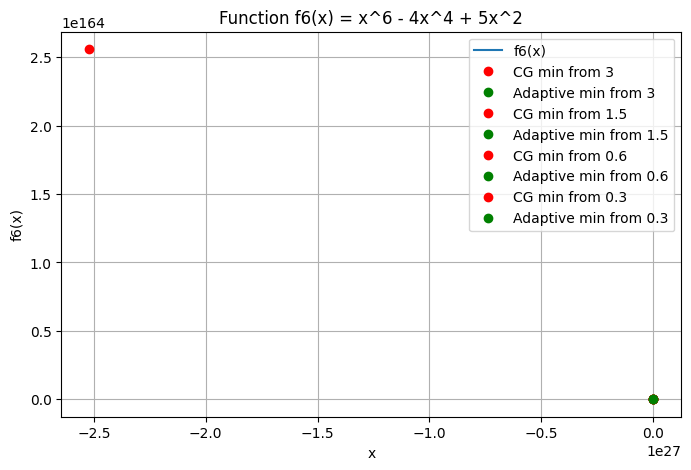

In [40]:
f6 = lambda x: x**6 - 4 * x**4 + 5 * x**2
df6 = lambda x: 6 * x**5 - 16 * x**3 + 10 * x

# Work Here!
x0 = [3, 1.5, 0.6, 0.3]
for x0_i in x0:
    result = optimize.minimize(df6, x0_i, method='CG')
    print(f"Scipy CG: Starting at {x0_i}, minimum found at x = {result.x} after {result.nit} iterations.")
    x_min_adaptive, iters_adaptive = gradient_adaptive(df6, x0_i)
    print(f"Adaptive Gradient: Starting at {x0_i}, minimum found at x = {x_min_adaptive} after {iters_adaptive} iterations.")

plt.figure(figsize=(8, 5))
x_plot = np.linspace(-3, 3, 400)
plt.plot(x_plot, f6(x_plot), label="f6(x)")
plt.title("Function f6(x) = x^6 - 4x^4 + 5x^2")
plt.xlabel("x")
plt.ylabel("f6(x)")
for x0_i in x0:
    result = optimize.minimize(df6, x0_i, method='CG')
    plt.plot(result.x, f6(result.x), 'ro', label=f"CG min from {x0_i}")
    x_min_adaptive, iters_adaptive = gradient_adaptive(df6, x0_i)
    plt.plot(x_min_adaptive, f6(x_min_adaptive), 'go', label=f"Adaptive min from {x0_i}")
plt.legend()
plt.grid(True)
plt.show()

#### 4b. Simulated annealing

The gradient methods only go down, so they can get stuck. Simulated annealing sometimes accepts a step upwards. At high temperature it moves almost freely, and as we cool it, it settles in a deep minimum.

1. Move: $x_\mathrm{new}=x+\delta$, where $\delta$ is uniform in $[-d,d)$.
2. Let $\Delta f=f(x_\mathrm{new})-f(x)$.
   * If $\Delta f\leq0$, accept the move.
   * If $\Delta f>0$, accept it with probability $e^{-\Delta f/T}$: accept if `rng.random() < np.exp(-df/T)`. Otherwise stay at $x$.
3. Cooling: step $k$ uses `temperatures[k]`. Make the temperatures with `np.geomspace(T0, T_end, n_steps)`.

Write `annealing(f, x0, temperatures, d, rng)`. It returns the positions after every step.

Run it from $x_0=3$ with $T_0=5$, $T_\mathrm{end}=10^{-3}$, $10^4$ steps and $d=0.1$, and plot $x$ against the step number. Run it 20 times. How many times does it end near $0$ ($|x|<0.3$)?

What happens with only 200 steps?

In [51]:
def annealing(f, x0, temperatures, d, rng):
    x = x0
    fx = f(x)
    path = [x]
    for T in temperatures:
        # Work Here!
        x_new = x + rng.uniform(-d, d)
        fx_new = f(x_new)
        if fx_new < fx or rng.uniform(0, 1) < np.exp((fx - fx_new) / T):
            x = x_new
            fx = fx_new
        path.append(x)
    return np.array(path)

0.007251899435290657
20


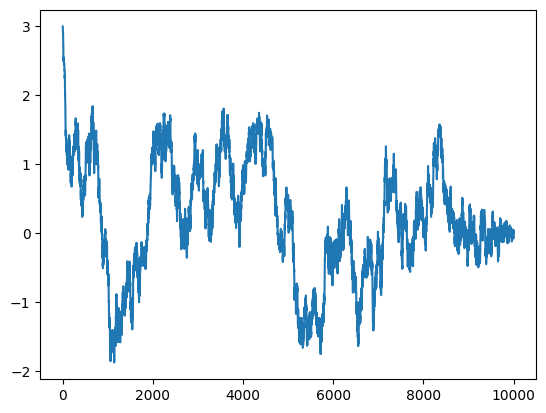

In [69]:
# Work Here!
path = annealing(f6, 3, np.linspace(5, 1e-3, num=10_000), 0.1, rng)
plt.plot(path)

print(path[-1])

ok = 0
for i in range(20):
    path = annealing(f6, 3, np.linspace(5, 1e-3, num=10_000), 0.1, rng)
    if np.abs(path[-1]) < 0.3:
        ok = ok + 1

print(ok)

### Task 5: Travelling salesman

We put $N$ random cities in the unit square. The salesman visits each city once and goes back to the start, in straight lines. We want a short route. There are $(N-1)!/2$ possible routes, so we cannot check all of them.

The route is an array `order` with the city indices in the order of visit. `tour_length` and `plot_tour` are given.

**The move (2-opt):** the best route never crosses itself. Pick two positions $i<j$, and reverse the part `order[i+1 : j+1]`. This replaces the edges `order[i] → order[i+1]` and `order[j] → order[j+1]` with `order[i] → order[j]` and `order[i+1] → order[j+1]`. In the picture the red route crosses itself, and the green one is the result of this move.

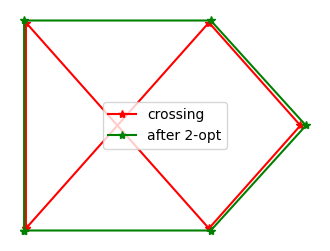

In [70]:
plt.figure(figsize=(4, 3))
plt.plot([0, 1, 1.5, 1, 0, 0], [0, 1, 0.5, 0, 1, 0], "r*-", label="crossing")
plt.plot([-0.01, 1.01, 1.53, 1.01, -0.01, -0.01], [-0.01, -0.01, 0.5, 1.01, 1.01, -0.01], "g*-", label="after 2-opt")
plt.legend(); plt.axis("off")
plt.show()

1. Write `two_opt(order, i, j)`. It returns a new array where `order[i+1 : j+1]` is reversed (`[::-1]`). Assume `i < j`.
2. Write `tsp_search(cities, order, temperatures, rng)`. At each step pick two different random positions, sort them, try `two_opt`, and accept or reject it as in 4b. Return the final order and the list of route lengths.
3. With `temperatures = np.zeros(n_steps)` only shorter (or equal) routes are accepted. This is the greedy method. Run greedy and annealing for $N=40$ and $40\,000$ steps (annealing: $T_0=0.5$, $T_\mathrm{end}=10^{-3}$), from the same random route. Plot the length against the step number, and both final routes. Which one is shorter?

In [71]:
N_cities = 40
cities = rng.random((N_cities, 2))


def tour_length(order, cities):
    pts = cities[order]
    return np.sum(np.linalg.norm(pts - np.roll(pts, -1, axis=0), axis=1))


def plot_tour(order, cities, ax, title=""):
    pts = cities[np.append(order, order[0])]
    ax.plot(pts[:, 0], pts[:, 1], "o-", ms=4)
    ax.set(title=f"{title} L = {tour_length(order, cities):.3f}", aspect="equal")


def two_opt(order, i, j):
    new_order = order.copy()
    new_order[i + 1:j + 1] = new_order[i + 1:j + 1][::-1]
    return new_order


def tsp_search(cities, order, temperatures, rng):
    order = order.copy()
    L = tour_length(order, cities)
    lengths = []
    n = len(order)
    for T in temperatures:
        i, j = np.sort(rng.choice(n, size=2, replace=False))
        candidate = two_opt(order, i, j)
        candidate_L = tour_length(candidate, cities)
        delta_L = candidate_L - L

        if T == 0:
            accept = delta_L <= 0
        else:
            accept = delta_L <= 0 or rng.random() < np.exp(-delta_L / T)

        if accept:
            order = candidate
            L = candidate_L

        lengths.append(L)
    return order, lengths

In [ ]:
n_steps = 40000
start_order = np.arange(N_cities)
rng.shuffle(start_order)

greedy_temperatures = np.zeros(n_steps)
annealing_temperatures = np.geomspace(0.5, 1e-3, n_steps)

greedy_order, greedy_lengths = tsp_search(
    cities, start_order, greedy_temperatures, rng
)
annealing_order, annealing_lengths = tsp_search(
    cities, start_order, annealing_temperatures, rng
)

print(f"Greedy final length: {greedy_lengths[-1]:.6f}")
print(f"Annealing final length: {annealing_lengths[-1]:.6f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(greedy_lengths, label="Greedy")
axes[0].plot(annealing_lengths, label="Annealing")
axes[0].set(xlabel="Step", ylabel="Route length", title="Route length by step")
axes[0].legend()

plot_tour(greedy_order, cities, axes[1], "Greedy")
plot_tour(annealing_order, cities, axes[2], "Annealing")
plt.tight_layout()
plt.show()
